In [16]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import scienceplots
plt.style.use(['science', 'nature', 'grid'])

import numpy as np
from scipy.interpolate import interp1d
import pandas as pd

from LoadMoments import *
from LoadTSV import *

In [17]:
# mpl.use('pgf')
mpl.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10,        # Match your LaTeX document font size
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8
})

In [18]:
# Plotting
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']
linestyles = ['-', '--', '-.', (0, (3, 1, 1, 1)), (0, (5, 1))]

# Parameter
M = 4
closure = "ExtGram"
Kn = 1.0
source_string = "relaxation_source"
T_end = 0.3
base_tree_level = 10
polydeg = 1
rho_L = 7.0
v_L1 = 0.0
v_L2 = 0.0
v_L3 = 0.0
theta_L = 1.0
rho_R = 1.0
v_R1 = 0.0
v_R2 = 0.0
v_R3 = 0.0
theta_R = 1.0

marker = ['o', 's', '^', 'x', 'd']
angle_indizes = [1, 2, 3]

# Kn and relaxation for solution files
M_vec = [4, 6, 8]
source = 'relaxation_source'
name = lambda M, angleindex, Kn, source_string: f"../out/1D3V_full/1D3V_M{M}_closure{closure}_Kn{Kn}_source{source_string}_angleindex{angleindex}_cons.tsv"

In [19]:
# for M in M_vec:
#     fig_shared, axs_shared = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(6, 3))
#     fig_shared.suptitle(f'1D-3V Full: M={M}, all angle indices', fontsize=12)

#     twx_shared = [ax.twinx() for ax in axs_shared]
#     for twx in twx_shared[1:]:
#         twx.sharey(twx_shared[0])
#     for twx in twx_shared:
#         twx.grid(False)
#     for twx in twx_shared[:-1]:
#         twx.tick_params(labelright=False)      # right tick labels only on the last column

#     for ax in axs_shared:
#         ax.set_xlim(-1.3, 1.3)
#         ax.set_xlabel('x')
#     axs_shared[0].set_ylabel(r'$\rho, p$')
#     twx_shared[-1].set_ylabel('$v$')

#     for color, label in zip(colors, [r'$\rho$', r'$v$', r'$p$']):
#         axs_shared[0].plot([], [], color=color, label=label)


#     # 3. Data Loop with Row and Column Titles
#     for row, angle_index in enumerate(angle_indizes):
#         kn_titles = [r'Kn=0.1', r'Kn=1.0', r'Kn$\to \infty$']

#         for column, (Kn, source) in enumerate([(0.1, 'relaxation_source'), (1.0, 'relaxation_source'), (10.0, 'zero_source')]):
#             print(f"Processing M={M}, Kn={Kn}, source={source}, angle_pair={angle_index}")
#             solution_file = name(M, angle_index, Kn, source)
#             data = read_solution_file(solution_file)
            
#             times = np.array([data[ts]["t"] for ts in sorted(data.keys())])
#             timesteps = np.array(sorted(data.keys()))

#             if len(timesteps) != 11: # Solution diverged before
#                 print(f"Warning: Expected 11 timesteps for M={M}, Kn={Kn}, source={source}, angle_pair={angle_index}, but got {len(timesteps)}. Skipping this case.")
#                 continue  # Skip this iteration if the number of timesteps is not as expected
            
#             time_query = 21 
#             sol = interpolate_solution(data, time_query, times, timesteps)
#             x, U = sol["x"], sol["u"]

#             rho = U[:, 0]
#             v = U[:, 1] / U[:, 0] # vx
#             theta = 1 / (3 * rho) * (U[:, 4] + U[:, 7] + U[:, 9] - rho * v**2) 
#             p = rho * theta

#             n_markers = 8                                   # per curve, tune to taste
#             step = max(len(x) // n_markers, 1)
#             offset = row * step // len(angle_indizes)       # 0, step/3, 2*step/3
#             style = dict(linestyle=linestyles[row], marker=marker[row],
#                         markevery=(offset, step), markersize=4, markerfacecolor='none')

#             axs_shared[column].plot(x, rho, color=colors[0], **style)
#             twx_shared[column].plot(x, v,   color=colors[1], **style)
#             axs_shared[column].plot(x, p,   color=colors[2], **style)

#     axs_shared[0].plot([], [], color='black', linestyle=linestyles[0], label=r'Angle Index 1', marker=marker[0])
#     axs_shared[0].plot([], [], color='black', linestyle=linestyles[1], label=r'Angle Index 2', marker=marker[1])
#     axs_shared[0].plot([], [], color='black', linestyle=linestyles[2], label=r'Angle Index 3', marker=marker[2])

#     fig_shared.legend(loc='lower center', ncol=7)
#     fig_shared.tight_layout(rect=(0, 0.05, 1, 1))
#     fig_shared.savefig(f'../out/Figures/1D3V/full/AngleComparison_M{M}_shared.pdf')
#     fig_shared.show()

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_55678/1076930156.py:71: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


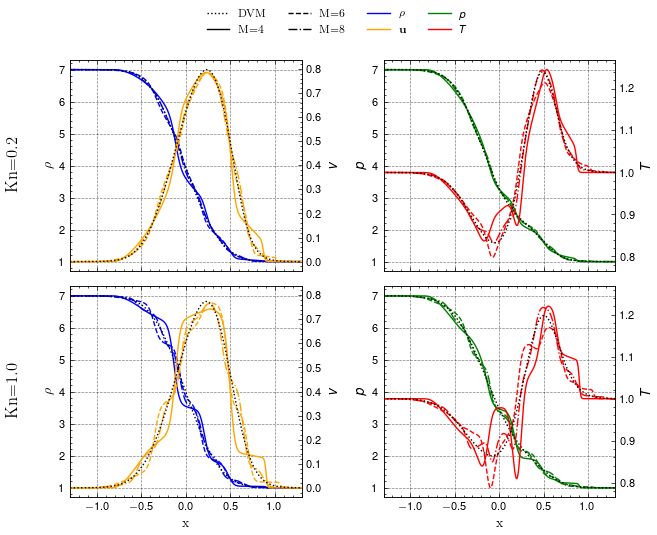

In [20]:
angle_index = 1
# fig, axs = plt.subplots(2, 2, figsize=(6.8, 5), sharex=True, sharey=False)
# primary axes: rho panels share y, p panels share y
fig, axs = plt.subplots(2, 2, figsize=(6.8, 5), sharex=True, sharey='col')

# twin axes: create them all first, then link row 1 to row 0
twx1 = [axs[row, 0].twinx() for row in range(2)]   # v
twx2 = [axs[row, 1].twinx() for row in range(2)]   # theta
twx1[1].sharey(twx1[0])
twx2[1].sharey(twx2[0])
for tw in twx1 + twx2:
    tw.grid(False)


for ax, label in zip(axs[:, 0], ['Kn=0.2', 'Kn=1.0']): # ToDo: 0.2
    ax.set_ylabel("$\\rho$")
    ax.text(-0.25, 0.5, label, transform=ax.transAxes, rotation=90, va='center', ha='center', size='large', weight='bold')
for ax in axs[:, 1]:
    ax.set_ylabel("$p$")

for row, (Kn, source) in enumerate([(0.2, 'relaxation_source'), (1.0, 'relaxation_source')]):
    twx1[row].set_ylabel("$v$")
    twx2[row].set_ylabel("$T$")
    for M_index, M in enumerate([4, 6, 8]):
        solution_file = name(M, angle_index, Kn, source)
        data = read_solution_file(solution_file)
        
        times = np.array([data[ts]["t"] for ts in sorted(data.keys())])
        timesteps = np.array(sorted(data.keys()))

        if len(timesteps) != 11: # Solution diverged before
            print(f"Warning: Expected 11 timesteps for M={M}, Kn={Kn}, source={source}, angle_index={angle_index}, but got {len(timesteps)}. Skipping this case.")
            continue  # Skip this iteration if the number of timesteps is not as expected
        
        time_query = 21 
        sol = interpolate_solution(data, time_query, times, timesteps)
        x, U = sol["x"], sol["u"]

        rho = U[:, 0]
        v = U[:, 1] / U[:, 0] # vx
        theta = 1 / (3 * rho) * (U[:, 4] + U[:, 7] + U[:, 9] - rho * v**2) 
        p = rho * theta

        axs[row, 0].plot(x, rho, color=colors[0], linestyle=linestyles[M_index])
        twx1[row].plot(x, v, color=colors[1], linestyle=linestyles[M_index])
        
        axs[row, 1].plot(x, p, color=colors[2], linestyle=linestyles[M_index])
        twx2[row].plot(x, theta, color=colors[3], linestyle=linestyles[M_index])

        if M == 8:
            cols = ["x", "rho", "v", "theta", "p", "U300", "U120", "U400", "U220", "U500"]
            data_3V = np.loadtxt(f"../out/Reference/bgk_3V_rhoL7.0_Kn{Kn}_nx1024_nu400.csv", delimiter=",")
            ref_3V = {name: data_3V[:, i] for i, name in enumerate(cols[:-1])}
            axs[row, 0].plot(ref_3V["x"], ref_3V["rho"], "k:", label="DVM")
            twx1[row].plot(ref_3V["x"], ref_3V["v"], "k:", label="DVM")
            axs[row, 1].plot(ref_3V["x"], ref_3V["p"], "k:", label="DVM")
            twx2[row].plot(ref_3V["x"], ref_3V["theta"], "k:", label="DVM")

[ax.set_xlim(-1.3, 1.3) for ax in axs.flatten()]
axs[-1, 0].set_xlabel("x"); axs[-1, 1].set_xlabel("x")
[axs[0, 0].plot([], [], color='black', linestyle=linestyles[M_index], lw=1, label=f'M={M}') for M_index, M in enumerate([4, 6, 8])]
[axs[0, 0].plot([], [], color=color, label=label) for color, label in zip(colors, [r'$\rho$', r'$\textbf{u}$', r'$p$', r'$T$'])]

handles, labels = axs[0, 0].get_legend_handles_labels()
x_left, x_right = axs[0, 0].get_position().x0, axs[0, 1].get_position().x1
legend_ncol = 4
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=((x_left + x_right) / 2, 1.0), ncol=legend_ncol, frameon=False)

fig.tight_layout()
fig.savefig(f"../out/Figures/1D3V/full/KnComparison_rhoL_{7.0}.pdf", bbox_inches='tight')
fig.show()

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_55678/1435135863.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


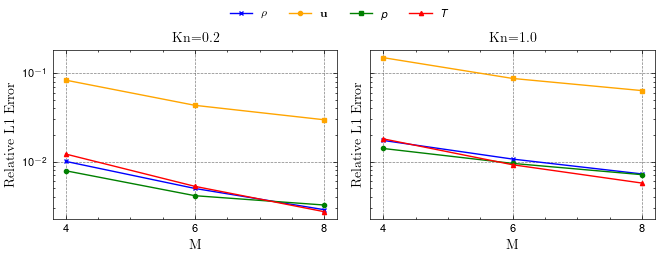

In [25]:
angle_index = 1
fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.5), sharex=True, sharey=True)

rel_errors = {}  # collected here, printed as a table in the next cell
for row, (Kn, source) in enumerate([(0.2, 'relaxation_source'), (1.0, 'relaxation_source')]): # ToDo: 0.2
    # twx1 = axs[row, 0].twinx(); twx1.grid(False); twx1.set_ylabel("$v$")
    # twx2 = axs[row, 1].twinx(); twx2.grid(False); twx2.set_ylabel("$T$")
    rel_l1_rho, rel_l1_v, rel_l1_p, rel_l1_theta = [], [], [], []
    for M_index, M in enumerate([4, 6, 8]):
        solution_file = name(M, angle_index, Kn, source)
        data = read_solution_file(solution_file)
        
        times = np.array([data[ts]["t"] for ts in sorted(data.keys())])
        timesteps = np.array(sorted(data.keys()))

        if len(timesteps) != 11: # Solution diverged before
            print(f"Warning: Expected 11 timesteps for M={M}, Kn={Kn}, source={source}, angle_index={angle_index}, but got {len(timesteps)}. Skipping this case.")
            continue  # Skip this iteration if the number of timesteps is not as expected
        
        time_query = 21 
        sol = interpolate_solution(data, time_query, times, timesteps)
        x, U = sol["x"], sol["u"]

        rho = U[:, 0]
        v = U[:, 1] / U[:, 0] # vx
        theta = 1 / (3 * rho) * (U[:, 4] + U[:, 7] + U[:, 9] - rho * v**2) 
        p = rho * theta

        cols = ["x", "rho", "v", "theta", "p", "U300", "U120", "U400", "U220", "U500"]
        data_3V = np.loadtxt(f"../out/Reference/bgk_3V_rhoL7.0_Kn{Kn}_nx1024_nu400.csv", delimiter=",")
        ref_3V = {name: data_3V[:, i] for i, name in enumerate(cols[:-1])}

        rho_interp = interp1d(x, rho, kind='linear', fill_value="extrapolate")
        v_interp = interp1d(x, v, kind='linear', fill_value="extrapolate")
        p_interp = interp1d(x, p, kind='linear', fill_value="extrapolate")
        theta_interp = interp1d(x, theta, kind='linear', fill_value="extrapolate")

        rel_l1_rho.append(np.sum(np.abs(rho_interp(ref_3V["x"]) - ref_3V["rho"])) / np.sum(np.abs(ref_3V["rho"])))
        rel_l1_v.append(np.sum(np.abs(v_interp(ref_3V["x"]) - ref_3V["v"])) / np.sum(np.abs(ref_3V["v"])))
        rel_l1_p.append(np.sum(np.abs(p_interp(ref_3V["x"]) - ref_3V["p"])) / np.sum(np.abs(ref_3V["p"])))
        rel_l1_theta.append(np.sum(np.abs(theta_interp(ref_3V["x"]) - ref_3V["theta"])) / np.sum(np.abs(ref_3V["theta"])))

    rel_errors[Kn] = {'rho': rel_l1_rho, 'v': rel_l1_v, 'p': rel_l1_p, 'theta': rel_l1_theta}
    axs[row].plot([4, 6, 8], rel_l1_rho, '-x', color=colors[0])
    axs[row].plot([4, 6, 8], rel_l1_p, '-o', color=colors[2])
    axs[row].plot([4, 6, 8], rel_l1_v, '-s', color=colors[1])
    axs[row].plot([4, 6, 8], rel_l1_theta, '-^', color=colors[3])

[axs[0].plot([], [], marker, color=color, label=label) for marker, color, label in zip(['-x', '-o', '-s', '-^'], colors, [r'$\rho$', r'$\textbf{u}$', r'$p$', r'$T$'])]
[ax.set_xticks([4, 6, 8]) for ax in axs]
[ax.set_xlabel("M") for ax in axs]
[ax.set_ylabel("Relative L1 Error") for ax in axs]
[ax.set_yscale('log') for ax in axs]
[ax.set_title(f"Kn={Kn}") for ax, (Kn, _) in zip(axs, [(0.2, 'relaxation_source'), (1.0, 'relaxation_source')])]

handles, labels = axs[0].get_legend_handles_labels()
x_left, x_right = axs[0].get_position().x0, axs[1].get_position().x1
legend_ncol = 4
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=((x_left + x_right) / 2, 0.95), ncol=legend_ncol, frameon=False)

fig.tight_layout()
fig.savefig(f"../out/Figures/1D3V/full/ModelConvergence_rhoL_{7.0}_closure{closure}.pdf", bbox_inches='tight')
fig.show()

In [26]:
# Relative L1 errors from the plot above as a table: once plain, once ready to paste into LaTeX
quantities = ['rho', 'v', 'p', 'theta']
tex_labels = {'rho': r'$\rho$', 'v': '$v$', 'p': '$p$', 'theta': r'$T$'}
M_err = [4, 6, 8]

# 1) plain table
rows = [{'Kn': Kn, 'M': M, **{q: errs[q][i] for q in quantities}}
        for Kn, errs in rel_errors.items() for i, M in enumerate(M_err)]
df_err = pd.DataFrame(rows).set_index(['Kn', 'M'])
print("Relative L1 error vs. DVM reference (rho_L = 7.0, angle index 1, t = 0.3)")
print(df_err.to_string(float_format=lambda x: f"{x:.3e}"))

# 2) LaTeX table (needs \usepackage{booktabs})
def tex_num(x):
    mant, exp = f"{x:.2e}".split('e')
    return rf"${mant} \times 10^{{{int(exp)}}}$"

lines = [r"\begin{tabular}{cccccc}", r"\toprule",
         r"$\mathrm{Kn}$ & $M$ & " + " & ".join(tex_labels[q] for q in quantities) + r" \\", r"\midrule"]
for Kn, errs in rel_errors.items():
    for i, M in enumerate(M_err):
        lines.append(f"{Kn if i == 0 else ''} & {M} & " + " & ".join(tex_num(errs[q][i]) for q in quantities) + r" \\")
    lines.append(r"\midrule")
lines[-1] = r"\bottomrule"
lines.append(r"\end{tabular}")
print()
print("\n".join(lines))

Relative L1 error vs. DVM reference (rho_L = 7.0, angle index 1, t = 0.3)
            rho         v         p     theta
Kn  M                                        
0.2 4 1.008e-02 8.307e-02 7.899e-03 1.219e-02
    6 4.982e-03 4.315e-02 4.129e-03 5.262e-03
    8 2.868e-03 2.965e-02 3.240e-03 2.723e-03
1.0 4 1.735e-02 1.489e-01 1.408e-02 1.807e-02
    6 1.069e-02 8.675e-02 9.556e-03 9.226e-03
    8 7.268e-03 6.326e-02 7.131e-03 5.732e-03

\begin{tabular}{cccccc}
\toprule
$\mathrm{Kn}$ & $M$ & $\rho$ & $v$ & $p$ & $T$ \\
\midrule
0.2 & 4 & $1.01 \times 10^{-2}$ & $8.31 \times 10^{-2}$ & $7.90 \times 10^{-3}$ & $1.22 \times 10^{-2}$ \\
 & 6 & $4.98 \times 10^{-3}$ & $4.31 \times 10^{-2}$ & $4.13 \times 10^{-3}$ & $5.26 \times 10^{-3}$ \\
 & 8 & $2.87 \times 10^{-3}$ & $2.96 \times 10^{-2}$ & $3.24 \times 10^{-3}$ & $2.72 \times 10^{-3}$ \\
\midrule
1.0 & 4 & $1.73 \times 10^{-2}$ & $1.49 \times 10^{-1}$ & $1.41 \times 10^{-2}$ & $1.81 \times 10^{-2}$ \\
 & 6 & $1.07 \times 10^{-2}$ & $8.